# Visualizaciones: libros más vendidos de Amazon (2009-2019)

Gráficos del análisis. Cada figura se guarda en `images/` para usarla en el README.

In [1]:
# Importar librerías
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

# Estilo general de los gráficos
print("=== CONFIGURACIÓN DE ESTILO ===")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.titlesize"] = 13

# Colores fijos por género, para que sean consistentes en todos los gráficos
COLORES = {"Fiction": "#4C72B0", "Non Fiction": "#DD8452"}

# Crear la carpeta images si no existe
os.makedirs("../images", exist_ok=True)

# Cargar el dataset limpio
print("\n=== CARGA DEL DATASET LIMPIO ===")
df = pd.read_csv("../data/processed/amazon_bestsellers_clean.csv")

# Subconjunto sin libros gratuitos para los análisis de precio
df_pago = df[~df["is_free"]]
print("Filas totales:", len(df), "| Filas de pago:", len(df_pago))


# Función para guardar cada gráfico en la carpeta images
def guardar(nombre):
    ruta = f"../images/{nombre}.png"
    plt.savefig(ruta, bbox_inches="tight", dpi=150)
    print("Gráfico guardado en:", ruta)


# Función para acortar títulos largos y que quepan en los ejes
def acortar(texto, limite=42):
    # Quitar subtítulos después de ":" o paréntesis
    texto = texto.split(":")[0].split("(")[0].strip()
    return texto if len(texto) <= limite else texto[: limite - 1] + "…"

=== CONFIGURACIÓN DE ESTILO ===

=== CARGA DEL DATASET LIMPIO ===
Filas totales: 550 | Filas de pago: 538


=== GRÁFICO 1: LIBROS CON MÁS APARICIONES ===
Gráfico guardado en: ../images/01_libros_mas_recurrentes.png


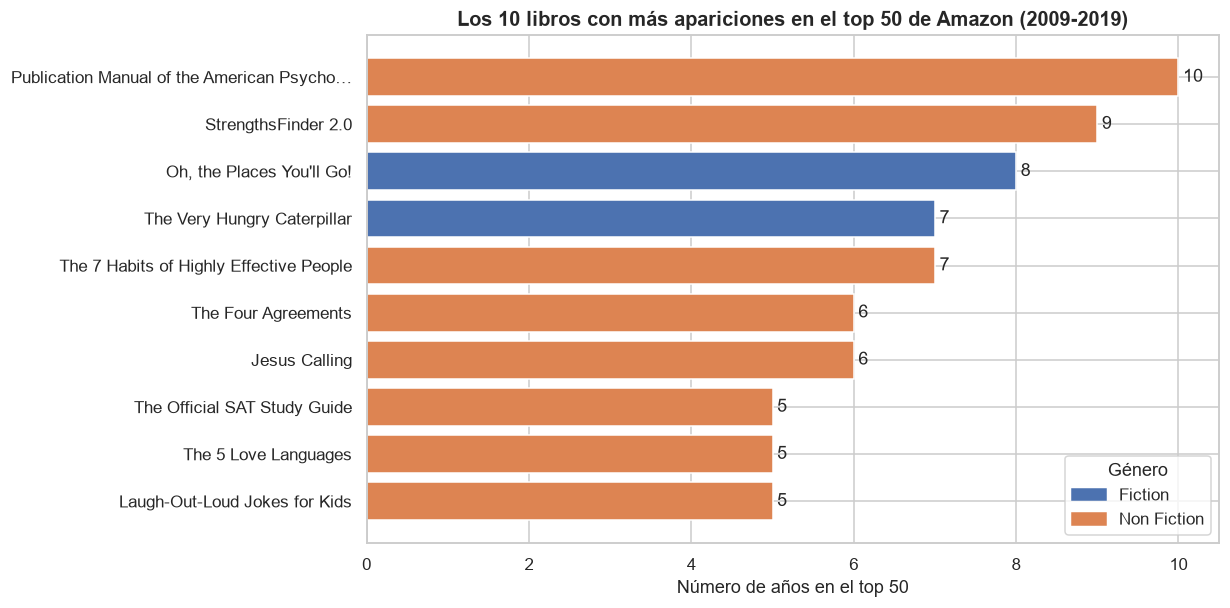

In [2]:
# GRÁFICO 1: libros con más apariciones en el top 50
print("=== GRÁFICO 1: LIBROS CON MÁS APARICIONES ===")

# Calcular apariciones por libro y género, y quedarnos con los 10 primeros
top_libros = (
    df.groupby(["name", "genre"])
    .size()
    .reset_index(name="apariciones")
    .sort_values("apariciones", ascending=False)
    .head(10)
)
top_libros["titulo_corto"] = top_libros["name"].apply(acortar)

# Dibujar barras horizontales, coloreadas según el género
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(
    top_libros["titulo_corto"],
    top_libros["apariciones"],
    color=top_libros["genre"].map(COLORES),
)
ax.invert_yaxis()  # el libro con más apariciones arriba
ax.bar_label(ax.containers[0], padding=3)  # mostrar el valor en cada barra

# Títulos y leyenda
ax.set_title("Los 10 libros con más apariciones en el top 50 de Amazon (2009-2019)")
ax.set_xlabel("Número de años en el top 50")
ax.set_ylabel("")
ax.legend(
    handles=[Patch(color=c, label=g) for g, c in COLORES.items()],
    title="Género",
    loc="lower right",
)

guardar("01_libros_mas_recurrentes")
plt.show()

=== GRÁFICO 2: AUTORES CON MÁS PRESENCIA ===
Gráfico guardado en: ../images/02_autores_con_mas_presencia.png


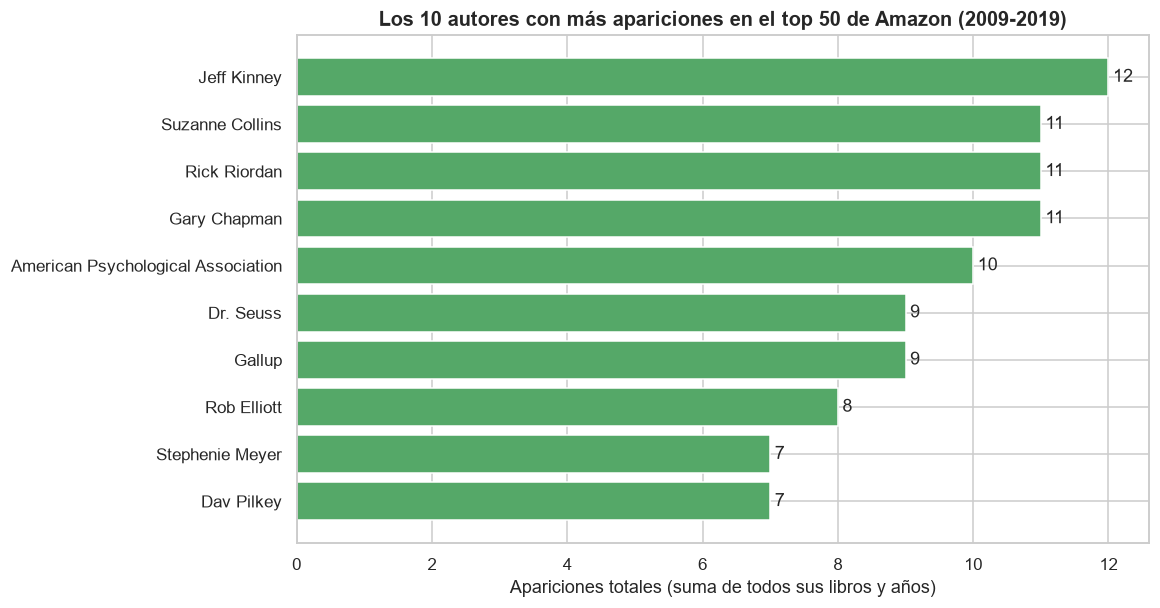

In [3]:
# GRÁFICO 2: autores con más apariciones en el top 50
print("=== GRÁFICO 2: AUTORES CON MÁS PRESENCIA ===")

# Contar apariciones por autor
top_autores = df["author"].value_counts().head(10)

# Dibujar barras horizontales
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_autores.index, top_autores.values, color="#55A868")
ax.invert_yaxis()
ax.bar_label(ax.containers[0], padding=3)

# Títulos
ax.set_title("Los 10 autores con más apariciones en el top 50 de Amazon (2009-2019)")
ax.set_xlabel("Apariciones totales (suma de todos sus libros y años)")
ax.set_ylabel("")

guardar("02_autores_con_mas_presencia")
plt.show()

=== GRÁFICO 3: FICCIÓN VS NO FICCIÓN POR AÑO ===
Gráfico guardado en: ../images/03_ficcion_vs_no_ficcion_por_anio.png


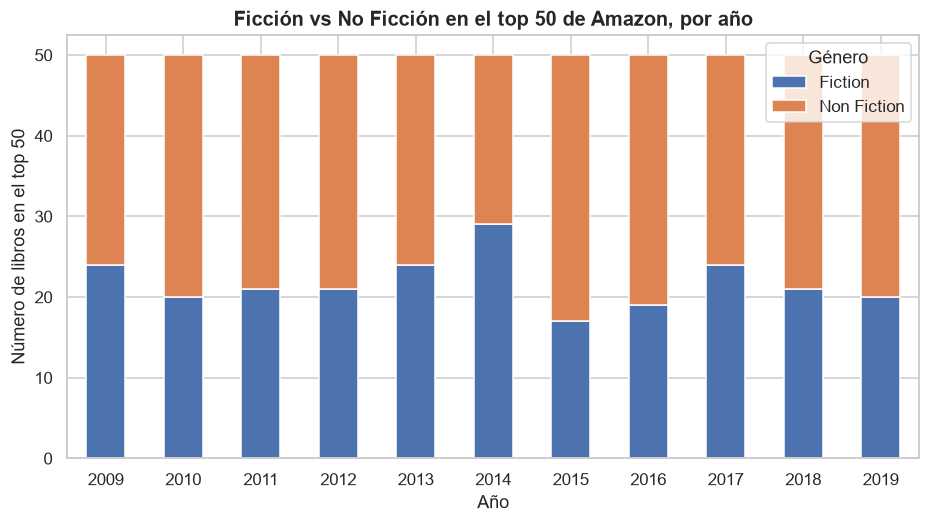

In [4]:
# GRÁFICO 3: apariciones por año según el género
print("=== GRÁFICO 3: FICCIÓN VS NO FICCIÓN POR AÑO ===")

# Tabla de conteo: años en filas, géneros en columnas
tabla_genero = pd.crosstab(df["year"], df["genre"])

# Barras apiladas (cada año suma 50 apariciones)
ax = tabla_genero.plot(
    kind="bar",
    stacked=True,
    color=[COLORES[g] for g in tabla_genero.columns],
    figsize=(10, 5),
)

# Títulos y formato
ax.set_title("Ficción vs No Ficción en el top 50 de Amazon, por año")
ax.set_xlabel("Año")
ax.set_ylabel("Número de libros en el top 50")
ax.legend(title="Género")
plt.xticks(rotation=0)

guardar("03_ficcion_vs_no_ficcion_por_anio")
plt.show()

=== GRÁFICO 4: EVOLUCIÓN DE PRECIO Y VALORACIÓN ===
Gráfico guardado en: ../images/04_evolucion_precio_y_valoracion.png


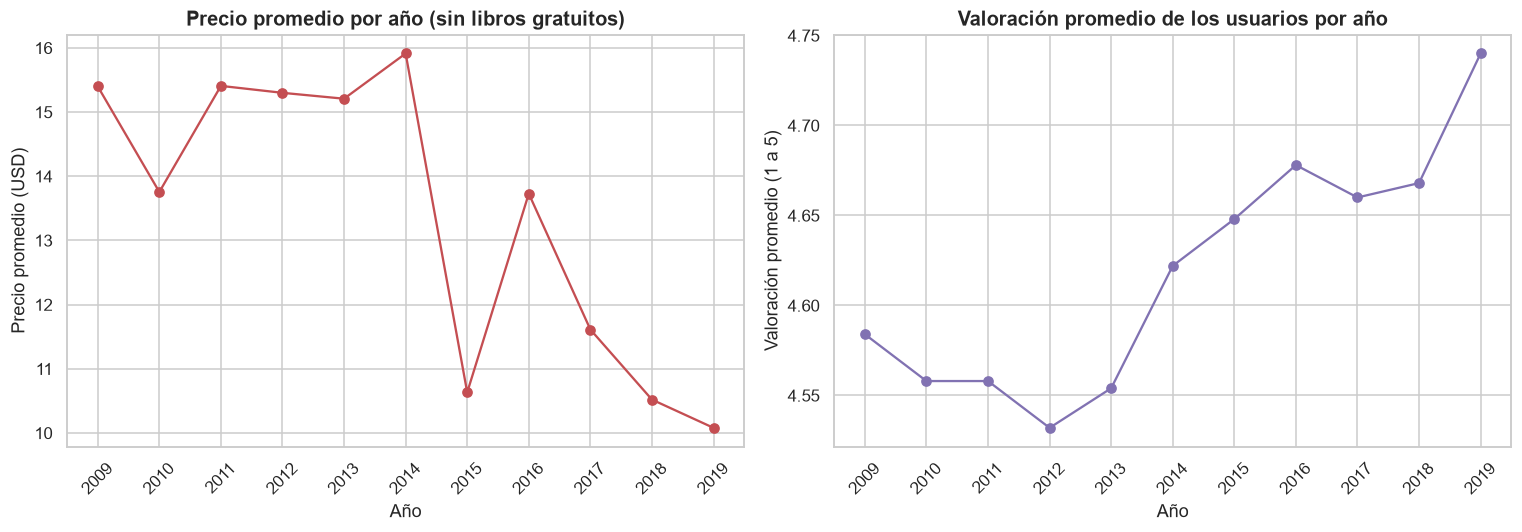

In [5]:
# GRÁFICO 4: evolución del precio promedio y de la valoración promedio
print("=== GRÁFICO 4: EVOLUCIÓN DE PRECIO Y VALORACIÓN ===")

# Calcular promedios anuales (precio sin libros gratuitos)
precio_anual = df_pago.groupby("year")["price"].mean()
rating_anual = df.groupby("year")["user_rating"].mean()

# Dos gráficos de línea lado a lado
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))

# Izquierda: precio promedio
ejes[0].plot(precio_anual.index, precio_anual.values, marker="o", color="#C44E52")
ejes[0].set_title("Precio promedio por año (sin libros gratuitos)")
ejes[0].set_xlabel("Año")
ejes[0].set_ylabel("Precio promedio (USD)")
ejes[0].set_xticks(precio_anual.index)
ejes[0].tick_params(axis="x", rotation=45)

# Derecha: valoración promedio
ejes[1].plot(rating_anual.index, rating_anual.values, marker="o", color="#8172B2")
ejes[1].set_title("Valoración promedio de los usuarios por año")
ejes[1].set_xlabel("Año")
ejes[1].set_ylabel("Valoración promedio (1 a 5)")
ejes[1].set_xticks(rating_anual.index)
ejes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
guardar("04_evolucion_precio_y_valoracion")
plt.show()

=== GRÁFICO 5: CORRELACIONES ===
Gráfico guardado en: ../images/05_correlaciones.png


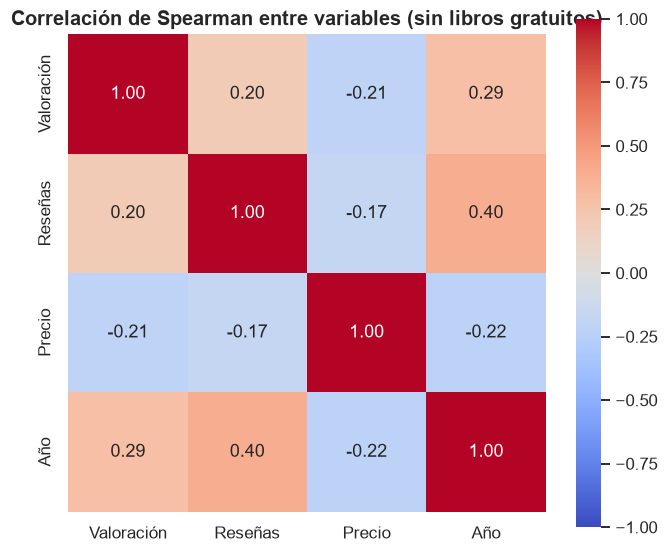

In [6]:
# GRÁFICO 5: mapa de calor de correlaciones (Spearman)
print("=== GRÁFICO 5: CORRELACIONES ===")

# Spearman porque reseñas y precios tienen valores extremos
columnas_num = ["user_rating", "reviews", "price", "year"]
correlaciones = df_pago[columnas_num].corr(method="spearman")

# Nombres más legibles para los ejes
etiquetas = {
    "user_rating": "Valoración",
    "reviews": "Reseñas",
    "price": "Precio",
    "year": "Año",
}
correlaciones = correlaciones.rename(index=etiquetas, columns=etiquetas)

# Dibujar el mapa de calor
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    correlaciones,
    annot=True,        # mostrar el valor en cada celda
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=ax,
)
ax.set_title("Correlación de Spearman entre variables (sin libros gratuitos)")

guardar("05_correlaciones")
plt.show()

In [7]:
# Verificar los archivos generados en la carpeta images
print("=== ARCHIVOS EN images/ ===")
for archivo in sorted(os.listdir("../images")):
    print("-", archivo)

=== ARCHIVOS EN images/ ===
- 01_libros_mas_recurrentes.png
- 02_autores_con_mas_presencia.png
- 03_ficcion_vs_no_ficcion_por_anio.png
- 04_evolucion_precio_y_valoracion.png
- 05_correlaciones.png
